# StyleBot Preparación común de datos

    Este notebook prepara la parte del líder para la primera entrega: cargar Fashion-MNIST, separar datos, comprobar categorías y generar evidencia para el equipo. No entrena clasificadores.

    **Responsable:** Angel Uriel Martinez Godinez

    **Cómo usarlo:** abre el archivo en Google Colab y ejecuta las celdas de arriba hacia abajo. Para este trabajo basta el entorno normal de CPU. Conserva una copia en tu Google Drive. La primera ejecución necesita conexión a Internet para descargar el dataset.

    **Estado del archivo:** es una plantilla lista para ejecutar, con salidas vacías. Las comprobaciones que aparecen al ejecutarlo corresponden a tu propia sesión. Lee y explica el código; cita las fuentes y reconoce la asistencia utilizada según las reglas de tu curso.

## 1 Carga común para todo el equipo

    Esta celda define las categorías y las funciones. Todos deben conservarla igual. `X` contiene imágenes y `y` las categorías correctas.

    La prueba oficial tiene 10,000 imágenes. De las otras 60,000 apartamos 20 % para validación: quedan 48,000 para entrenamiento y 12,000 para validación. `stratify` conserva la proporción de las categorías y la semilla 42 fija la división. Los píxeles ya quedan normalizados entre 0 y 1; no vuelvas a dividirlos entre 255.

In [2]:
import numpy as np
from sklearn.model_selection import train_test_split

SEMILLA = 42
CATEGORIAS = [
    "Camiseta", "Pantalón", "Suéter", "Vestido", "Abrigo",
    "Sandalia", "Camisa", "Tenis", "Bolso", "Botín"
]

def preparar_datos_stylebot(X_base, y_base, X_prueba, y_prueba):
    """Divide los 60,000 ejemplos originales y conserva la prueba oficial."""
    assert X_base.shape == (60000, 28, 28)
    assert y_base.shape == (60000,)
    assert X_prueba.shape == (10000, 28, 28)
    assert y_prueba.shape == (10000,)
    assert X_base.dtype == np.uint8 and X_prueba.dtype == np.uint8

    # Los índices permiten identificar exactamente las imágenes de cada parte.
    indices = np.arange(len(y_base), dtype=np.int64)
    idx_train, idx_val = train_test_split(
        indices, test_size=0.20, random_state=SEMILLA, stratify=y_base
    )

    # Normalizar una sola vez: uint8 de 0 a 255 -> float32 de 0 a 1.
    datos = {
        "X_train": X_base[idx_train].astype(np.float32) / np.float32(255.0),
        "y_train": y_base[idx_train].copy(),
        "X_val": X_base[idx_val].astype(np.float32) / np.float32(255.0),
        "y_val": y_base[idx_val].copy(),
        "X_test": X_prueba.astype(np.float32) / np.float32(255.0),
        "y_test": y_prueba.copy(),
        "idx_train": idx_train,
        "idx_val": idx_val,
        # Estos índices pertenecen al archivo de prueba, no al de entrenamiento.
        "idx_test": np.arange(len(y_prueba), dtype=np.int64),
    }
    return datos

def cargar_datos_stylebot():
    """Descarga Fashion-MNIST automáticamente mediante TensorFlow/Keras."""
    from tensorflow.keras.datasets import fashion_mnist
    (X_base, y_base), (X_prueba, y_prueba) = fashion_mnist.load_data()
    return preparar_datos_stylebot(X_base, y_base, X_prueba, y_prueba)


## 2 Descargar y preparar Fashion MNIST

    Ejecuta la siguiente celda. `fashion_mnist.load_data()` descarga automáticamente los archivos oficiales a través de TensorFlow/Keras.

    Esperamos estas formas: entrenamiento `(48000, 28, 28)`, validación `(12000, 28, 28)` y prueba `(10000, 28, 28)`. La descarga puede tardar la primera vez.

In [3]:
datos = cargar_datos_stylebot()
X_train, y_train = datos["X_train"], datos["y_train"]
X_val, y_val = datos["X_val"], datos["y_val"]
X_test, y_test = datos["X_test"], datos["y_test"]

print("Entrenamiento:", X_train.shape, y_train.shape)
print("Validación:   ", X_val.shape, y_val.shape)
print("Prueba:       ", X_test.shape, y_test.shape)
print("Píxeles:", X_train.dtype, "de", X_train.min(), "a", X_train.max())


29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Entrenamiento: (48000, 28, 28) (48000,)
Validación:    (12000, 28, 28) (12000,)
Prueba:        (10000, 28, 28) (10000,)
Píxeles: float32 de 0.0 a 1.0


## 3 Comprobar la división y los valores

    Las instrucciones `assert` detienen la ejecución si algo no coincide con lo esperado. Conservamos los índices de entrenamiento y validación para verificar que no se mezclaron. Los índices de prueba pertenecen a un archivo diferente.

    Revisamos forma, cantidad, rango, valores no finitos y categorías. Esto no equivale a una inspección exhaustiva de daños visuales ni a una búsqueda de duplicados de contenido.

In [4]:
# Esta comprobación NO evalúa modelos: verifica la preparación de datos.
assert len(np.intersect1d(datos["idx_train"], datos["idx_val"])) == 0
assert len(np.union1d(datos["idx_train"], datos["idx_val"])) == 60000

comprobaciones = []
for nombre, X, y, cantidad in [
    ("entrenamiento", X_train, y_train, 48000),
    ("validacion", X_val, y_val, 12000),
    ("prueba", X_test, y_test, 10000),
]:
    assert X.shape == (cantidad, 28, 28)
    assert y.shape == (cantidad,)
    assert X.dtype == np.float32
    assert np.isfinite(X).all()
    assert X.min() >= 0.0 and X.max() <= 1.0
    assert np.isin(y, np.arange(10)).all()
    conteos = np.bincount(y, minlength=10)
    assert np.all(conteos == cantidad // 10)
    comprobaciones.append({
        "conjunto": nombre, "imagenes": cantidad,
        "forma_imagen": "28x28", "tipo_pixeles": str(X.dtype),
        "minimo": float(X.min()), "maximo": float(X.max()),
        "valores_no_finitos": int((~np.isfinite(X)).sum()),
        "etiquetas_invalidas": int((~np.isin(y, np.arange(10))).sum()),
    })
    print(nombre, "OK:", cantidad, "imágenes;", conteos.tolist(), "por categoría")

print("OK: entrenamiento y validación no comparten índices.")
print("La prueba conserva las 10,000 imágenes del archivo oficial de prueba.")
print("Estas revisiones no demuestran ausencia de imágenes duplicadas o problemas visuales.")


entrenamiento OK: 48000 imágenes; [4800, 4800, 4800, 4800, 4800, 4800, 4800, 4800, 4800, 4800] por categoría
validacion OK: 12000 imágenes; [1200, 1200, 1200, 1200, 1200, 1200, 1200, 1200, 1200, 1200] por categoría
prueba OK: 10000 imágenes; [1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000] por categoría
OK: entrenamiento y validación no comparten índices.
La prueba conserva las 10,000 imágenes del archivo oficial de prueba.
Estas revisiones no demuestran ausencia de imágenes duplicadas o problemas visuales.


## 4 Ver las categorías y sus cantidades

    Los números tienen el mismo significado para todos los integrantes. Camiseta es 0 y camisa es 6; no deben intercambiarse. Con esta división esperamos 4,800 imágenes de entrenamiento, 1,200 de validación y 1,000 de prueba por categoría.

In [5]:
print("ID | Categoría | Entrenamiento | Validación | Prueba")
conteo_clases = []
for identificador, categoria in enumerate(CATEGORIAS):
    fila = {
        "id": identificador, "categoria": categoria,
        "entrenamiento": int(np.sum(y_train == identificador)),
        "validacion": int(np.sum(y_val == identificador)),
        "prueba": int(np.sum(y_test == identificador)),
    }
    conteo_clases.append(fila)
    print(f"{identificador:2} | {categoria:9} | {fila['entrenamiento']:5} | {fila['validacion']:5} | {fila['prueba']:5}")


ID | Categoría | Entrenamiento | Validación | Prueba
 0 | Camiseta  |  4800 |  1200 |  1000
 1 | Pantalón  |  4800 |  1200 |  1000
 2 | Suéter    |  4800 |  1200 |  1000
 3 | Vestido   |  4800 |  1200 |  1000
 4 | Abrigo    |  4800 |  1200 |  1000
 5 | Sandalia  |  4800 |  1200 |  1000
 6 | Camisa    |  4800 |  1200 |  1000
 7 | Tenis     |  4800 |  1200 |  1000
 8 | Bolso     |  4800 |  1200 |  1000
 9 | Botín     |  4800 |  1200 |  1000


## 5 Guardar las tablas y las reglas del equipo

    Se guardan categorías, conteos, comprobaciones, índices y un protocolo con la semilla, las versiones y las huellas de la división. El archivo de índices es pequeño: no contiene las imágenes.

    Si dos integrantes usan diferentes versiones, comparen las huellas en `protocolo_datos.json`. Si no coinciden, acuerden una misma versión o reutilicen los índices del líder antes de comparar modelos.

In [6]:
from pathlib import Path
import csv
import hashlib
import importlib.metadata
import json
import zipfile

# Todos los resultados se escriben en esta carpeta, dentro de la sesión actual.
CARPETA_SALIDA = Path("StyleBot_datos_generados")
for subcarpeta in ["datos", "resultados/tablas", "resultados/graficas"]:
    (CARPETA_SALIDA / subcarpeta).mkdir(parents=True, exist_ok=True)

def guardar_csv(ruta, filas):
    with ruta.open("w", newline="", encoding="utf-8-sig") as archivo:
        escritor = csv.DictWriter(archivo, fieldnames=list(filas[0].keys()))
        escritor.writeheader()
        escritor.writerows(filas)

guardar_csv(CARPETA_SALIDA / "datos/categorias.csv", [
    {"id": i, "categoria": nombre} for i, nombre in enumerate(CATEGORIAS)
])
guardar_csv(CARPETA_SALIDA / "resultados/tablas/conteo_clases.csv", conteo_clases)
guardar_csv(CARPETA_SALIDA / "resultados/tablas/verificacion_datos.csv", comprobaciones)

np.savez_compressed(
    CARPETA_SALIDA / "datos/particiones_semilla42.npz",
    idx_train=datos["idx_train"], idx_val=datos["idx_val"], idx_test=datos["idx_test"]
)

versiones = {}
for paquete in ["numpy", "scikit-learn", "matplotlib", "tensorflow"]:
    try:
        versiones[paquete] = importlib.metadata.version(paquete)
    except importlib.metadata.PackageNotFoundError:
        versiones[paquete] = "no detectado en este entorno"

huellas_indices = {
    nombre: hashlib.sha256(datos[nombre].astype("<i8").tobytes()).hexdigest()
    for nombre in ["idx_train", "idx_val", "idx_test"]
}
protocolo = {
    "dataset": "Fashion-MNIST", "semilla": SEMILLA,
    "entrenamiento": 48000, "validacion": 12000, "prueba": 10000,
    "origen_train_val": "60,000 imágenes oficiales de entrenamiento",
    "origen_test": "10,000 imágenes oficiales de prueba, conservadas",
    "separacion": "train_test_split, test_size=0.20, stratify=y_base",
    "forma_imagen": [28, 28], "normalizacion": "float32 / 255.0, una sola vez",
    "categorias": {str(i): nombre for i, nombre in enumerate(CATEGORIAS)},
    "sha256_indices": huellas_indices, "versiones": versiones,
}
(CARPETA_SALIDA / "datos/protocolo_datos.json").write_text(
    json.dumps(protocolo, indent=2, ensure_ascii=False), encoding="utf-8"
)
print("Resultados guardados en:", CARPETA_SALIDA.resolve())
print("Huella de la división de entrenamiento:", huellas_indices["idx_train"])


Resultados guardados en: /content/StyleBot_datos_generados
Huella de la división de entrenamiento: 1c0cffec1476c830767b282ef3e3354d14cb1e3e2ecb436f13ee8537f0de19c9


## 6 Mostrar ejemplos y distribución

    Estas figuras sirven para revisar que las categorías y sus imágenes tengan sentido. La selección de ejemplos utiliza únicamente entrenamiento.

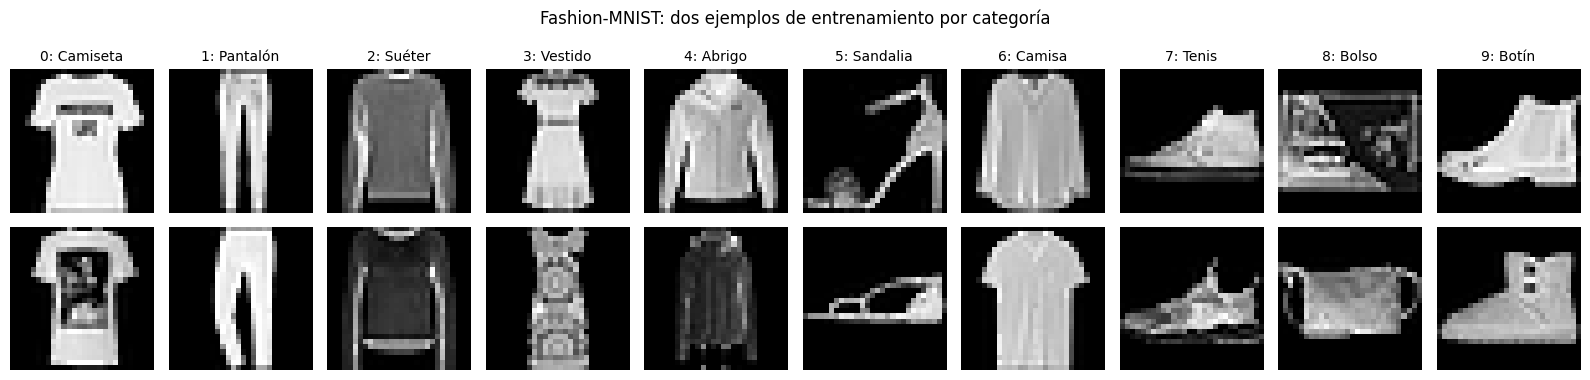

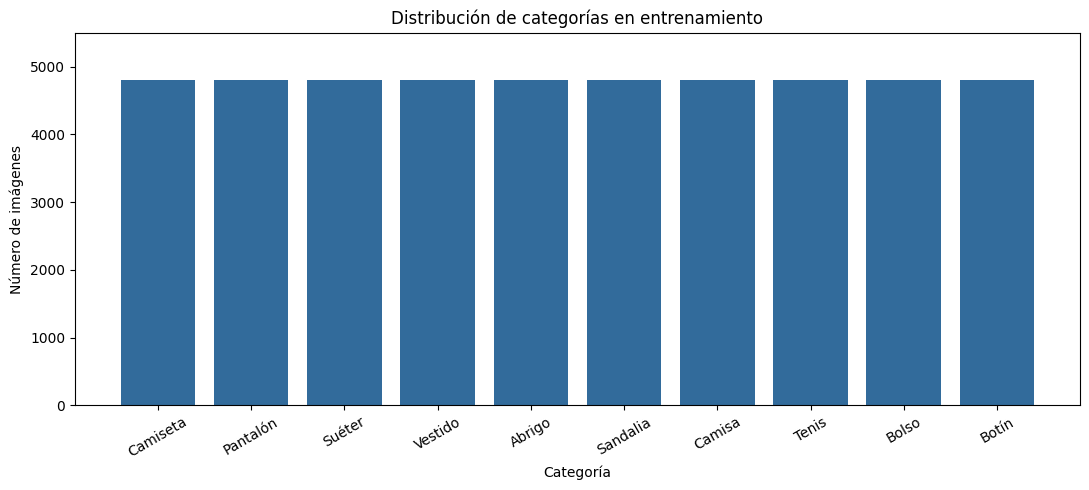

In [7]:
import matplotlib.pyplot as plt

# Solo usamos entrenamiento para elegir los ejemplos exploratorios.
fig, ejes = plt.subplots(2, 10, figsize=(16, 4))
for categoria_id, nombre in enumerate(CATEGORIAS):
    ejemplos = np.flatnonzero(y_train == categoria_id)[:2]
    for fila, indice in enumerate(ejemplos):
        ejes[fila, categoria_id].imshow(X_train[indice], cmap="gray", vmin=0, vmax=1)
        ejes[fila, categoria_id].axis("off")
        if fila == 0:
            ejes[fila, categoria_id].set_title(f"{categoria_id}: {nombre}", fontsize=10)
fig.suptitle("Fashion-MNIST: dos ejemplos de entrenamiento por categoría")
fig.tight_layout()
fig.savefig(CARPETA_SALIDA / "resultados/graficas/ejemplos_prendas.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(CATEGORIAS, np.bincount(y_train, minlength=10), color="#326b9b")
ax.set_title("Distribución de categorías en entrenamiento")
ax.set_xlabel("Categoría")
ax.set_ylabel("Número de imágenes")
ax.tick_params(axis="x", rotation=30)
ax.set_ylim(0, 5500)
fig.tight_layout()
fig.savefig(CARPETA_SALIDA / "resultados/graficas/distribucion_entrenamiento.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)


## 7 Descargar los resultados para el equipo

    La siguiente celda descarga un ZIP con las tablas, figuras y protocolo. Guárdalo en tu computadora y extráelo antes de subir los archivos a GitHub.

    Además, descarga este notebook desde Archivo y Descargar como `.ipynb` después de ejecutarlo. Ese archivo conservará las salidas de tu sesión. El ZIP de resultados no incluye automáticamente el notebook.

In [8]:
ruta_zip = Path("StyleBot_datos_generados.zip")
with zipfile.ZipFile(ruta_zip, "w", zipfile.ZIP_DEFLATED) as comprimido:
    for ruta in sorted(CARPETA_SALIDA.rglob("*")):
        if ruta.is_file():
            comprimido.write(ruta, ruta.relative_to(CARPETA_SALIDA))
print("Archivo preparado:", ruta_zip.resolve())

# En Colab, esta línea ofrece el ZIP para descargar a tu computadora.
try:
    from google.colab import files
except ImportError:
    print("Fuera de Colab: abre el ZIP en la ruta indicada arriba.")
else:
    files.download(str(ruta_zip))


Archivo preparado: /content/StyleBot_datos_generados.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 8 Revisar y entregar

    - Comprueba que no haya errores y que las categorías coincidan con las imágenes.
    - Escribe tu nombre y una explicación con tus propias palabras.
    - Sube el notebook ejecutado, `categorias.csv`, `particiones_semilla42.npz`, `protocolo_datos.json`, tablas y gráficas.
    - Comparte el enlace del notebook y el protocolo con los cuatro compañeros.
    - Cada compañero puede abrir el notebook, guardar una copia con el nombre de su parte y conservar las celdas comunes de carga.
    - El conjunto de prueba se reserva para la evaluación final; no se usa para seleccionar parámetros, ajustar PCA o entrenar modelos.

    **Para el informe:** después de ejecutar, describe las cantidades observadas, el tipo de datos, la normalización y las comprobaciones realizadas. No afirmes que eliminaste imágenes dañadas o duplicadas si no hiciste esa revisión.

    **Fuentes**

    - TensorFlow. Fashion-MNIST load_data. https://www.tensorflow.org/api_docs/python/tf/keras/datasets/fashion_mnist/load_data
    - TensorFlow. Basic classification. https://www.tensorflow.org/tutorials/keras/classification
    - Scikit-learn. train_test_split. https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html
    - Zalando Research. Fashion-MNIST. https://github.com/zalandoresearch/fashion-mnist

In [9]:
!pip -q install scikit-image

Entrenamiento: (48000, 784)
Validación: (12000, 784)
Prueba: (10000, 784)

RESULTADO PRELIMINAR


,modelo,representacion,muestra_entrenamiento,tiempo_segundos,estado,accuracy,precision_ponderada,recall_ponderado,f1_ponderado,precision_macro,recall_macro,f1_macro
0,Regresión logística,Píxeles crudos,5000,8.90728,PRELIMINAR,0.803917,0.805141,0.803917,0.804266,0.805141,0.803917,0.804266


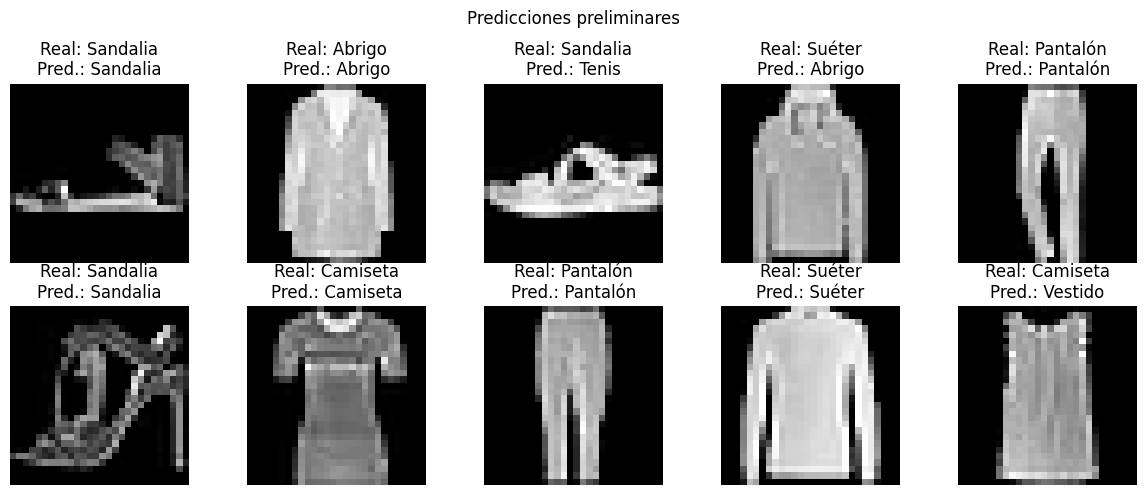


Calculando PCA...
Varianza explicada por PCA: 91.19%

Entrenando: Regresión logística con Píxeles crudos

Entrenando: Regresión logística con PCA (100 componentes)

Entrenando: SVM lineal con Píxeles crudos

Entrenando: SVM lineal con PCA (100 componentes)

Entrenando: Random Forest con Píxeles crudos

Entrenando: Random Forest con PCA (100 componentes)

TABLA COMPARATIVA PRELIMINAR


,modelo,representacion,tiempo_segundos,estado,accuracy,precision_ponderada,recall_ponderado,f1_ponderado,precision_macro,recall_macro,f1_macro
0,Random Forest,Píxeles crudos,112.284371,PRELIMINAR,0.884167,0.883595,0.884167,0.883142,0.883595,0.884167,0.883142
1,Random Forest,PCA (100 componentes),137.579948,PRELIMINAR,0.874167,0.873397,0.874167,0.872784,0.873397,0.874167,0.872784
2,Regresión logística,Píxeles crudos,58.474065,PRELIMINAR,0.856167,0.855454,0.856167,0.855683,0.855454,0.856167,0.855683
3,SVM lineal,Píxeles crudos,205.799018,PRELIMINAR,0.856083,0.854332,0.856083,0.854544,0.854332,0.856083,0.854544
4,Regresión logística,PCA (100 componentes),4.325852,PRELIMINAR,0.854333,0.853056,0.854333,0.853471,0.853056,0.854333,0.853471
5,SVM lineal,PCA (100 componentes),9.573643,PRELIMINAR,0.850667,0.848661,0.850667,0.848699,0.848661,0.850667,0.848699



Mejores representaciones:
{'Random Forest': 'Píxeles crudos', 'Regresión logística': 'Píxeles crudos', 'SVM lineal': 'Píxeles crudos'}

Ajustando: Regresión logística con Píxeles crudos
Fitting 3 folds for each of 3 candidates, totalling 9 fits

Ajustando: SVM lineal con Píxeles crudos
Fitting 3 folds for each of 3 candidates, totalling 9 fits

Ajustando: Random Forest con Píxeles crudos
Fitting 3 folds for each of 4 candidates, totalling 12 fits

Extrayendo HOG + Hu de entrenamiento...
Entrenamiento: 5000/48000
Entrenamiento: 10000/48000
Entrenamiento: 15000/48000
Entrenamiento: 20000/48000
Entrenamiento: 25000/48000
Entrenamiento: 30000/48000
Entrenamiento: 35000/48000
Entrenamiento: 40000/48000
Entrenamiento: 45000/48000

Extrayendo HOG + Hu de validación...
Validación: 5000/12000
Validación: 10000/12000

Ajustando regresión logística con HOG + Hu...
Fitting 3 folds for each of 4 candidates, totalling 12 fits

RESULTADOS DESPUÉS DE VALIDACIÓN CRUZADA


,candidato,modelo,representacion,mejores_parametros,f1_macro_cv,tiempo_ajuste_cv_segundos,accuracy,precision_ponderada,recall_ponderado,f1_ponderado,precision_macro,recall_macro,f1_macro
0,Regresión logística (HOG + Hu),Regresión logística,HOG + momentos de Hu,"{""modelo__C"": 0.01}",0.859910,63.827605,0.890083,0.889996,0.890083,0.890013,0.889996,0.890083,0.890013
1,Random Forest (Píxeles crudos),Random Forest,Píxeles crudos,"{""modelo__max_depth"": null, ""modelo__n_estimat...",0.853948,194.269799,0.884167,0.883595,0.884167,0.883142,0.883595,0.884167,0.883142
2,Regresión logística (Píxeles crudos),Regresión logística,Píxeles crudos,"{""modelo__C"": 0.1}",0.825068,63.921092,0.857667,0.856931,0.857667,0.857170,0.856931,0.857667,0.857170
3,SVM lineal (Píxeles crudos),SVM lineal,Píxeles crudos,"{""modelo__C"": 0.01}",0.817829,1022.493622,0.857333,0.855448,0.857333,0.855644,0.855448,0.857333,0.855644



Extrayendo HOG + Hu de prueba...
Prueba: 5000/10000
Prueba: 10000/10000

Evaluando en prueba: Regresión logística (Píxeles crudos)


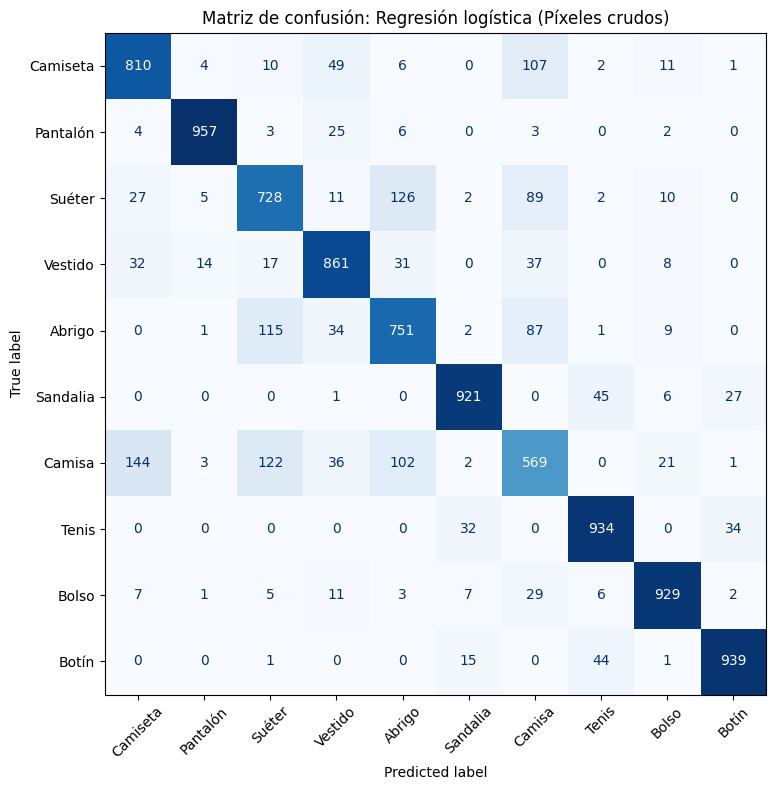


Evaluando en prueba: SVM lineal (Píxeles crudos)


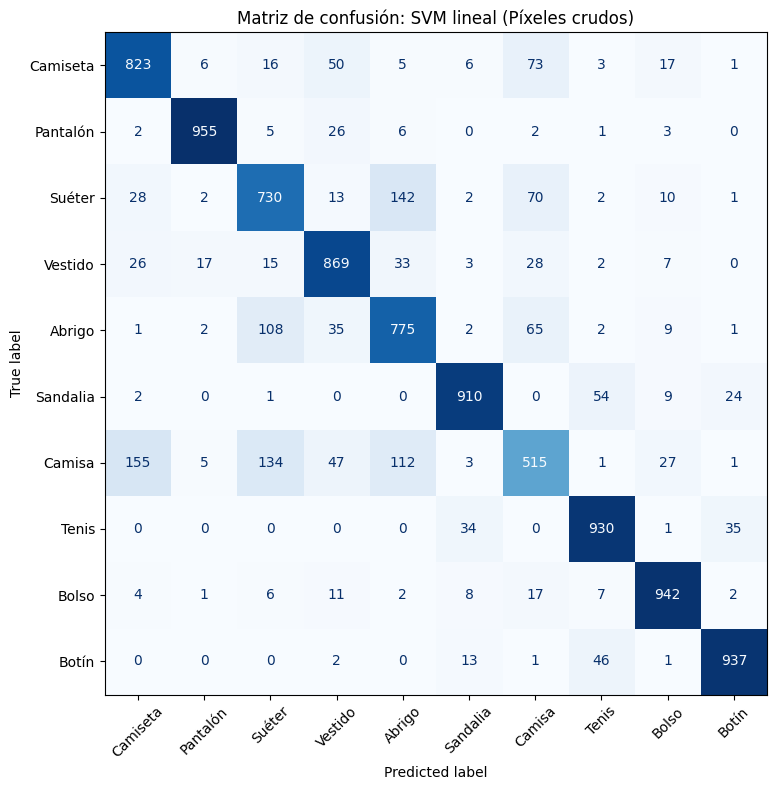


Evaluando en prueba: Random Forest (Píxeles crudos)


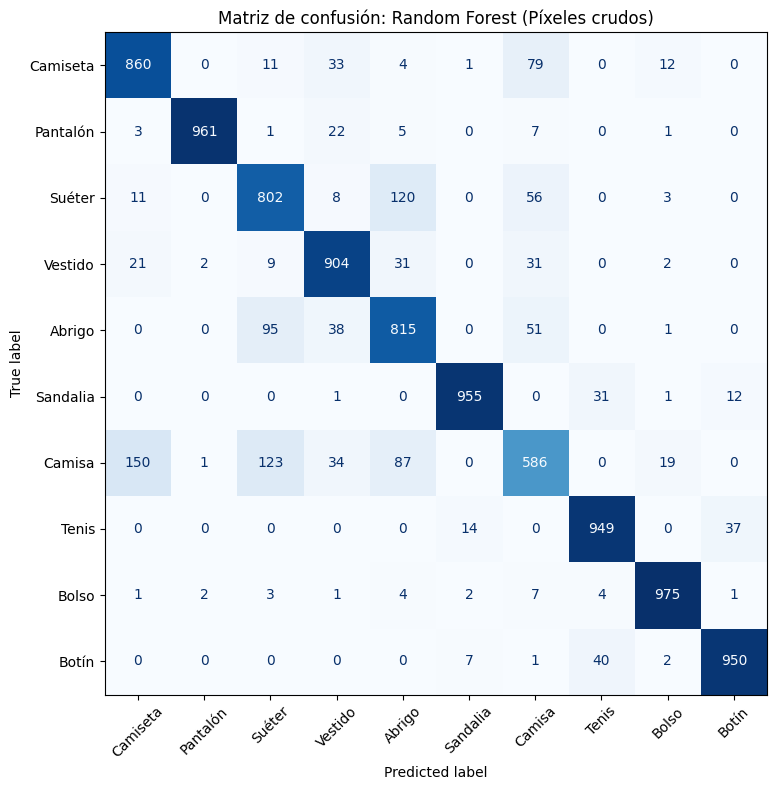


Evaluando en prueba: Regresión logística (HOG + Hu)


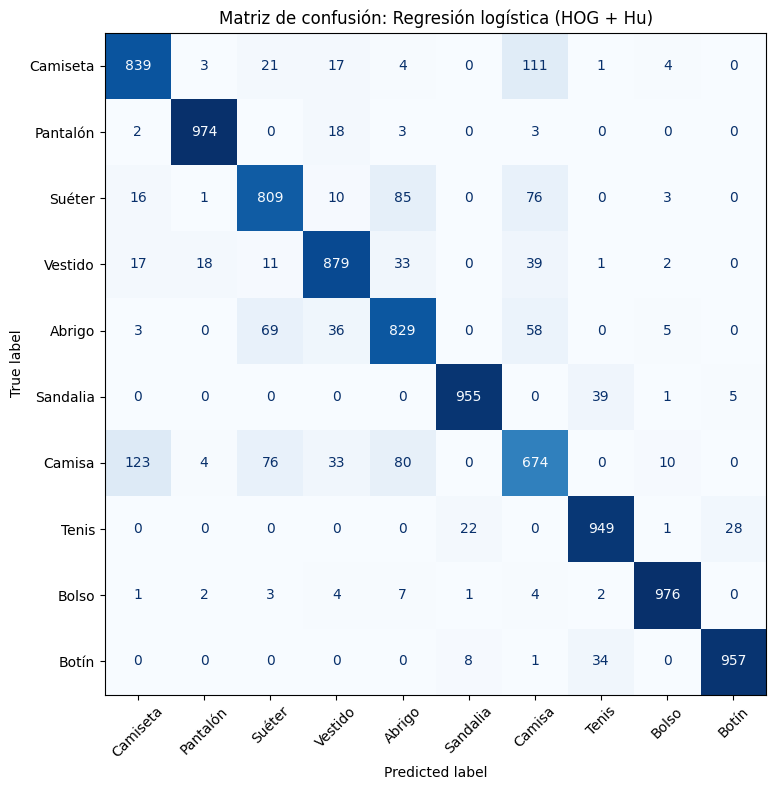


MÉTRICAS FINALES


,candidato,accuracy,precision_ponderada,recall_ponderado,f1_ponderado,precision_macro,recall_macro,f1_macro
0,Regresión logística (HOG + Hu),0.8841,0.883816,0.8841,0.883879,0.883816,0.8841,0.883879
1,Random Forest (Píxeles crudos),0.8757,0.874641,0.8757,0.874263,0.874641,0.8757,0.874263
2,Regresión logística (Píxeles crudos),0.8399,0.838708,0.8399,0.839125,0.838708,0.8399,0.839125
3,SVM lineal (Píxeles crudos),0.8386,0.835884,0.8386,0.835985,0.835884,0.8386,0.835985



Modelo elegido por F1 macro de validación: Regresión logística (HOG + Hu)
Cantidad de errores: 1159


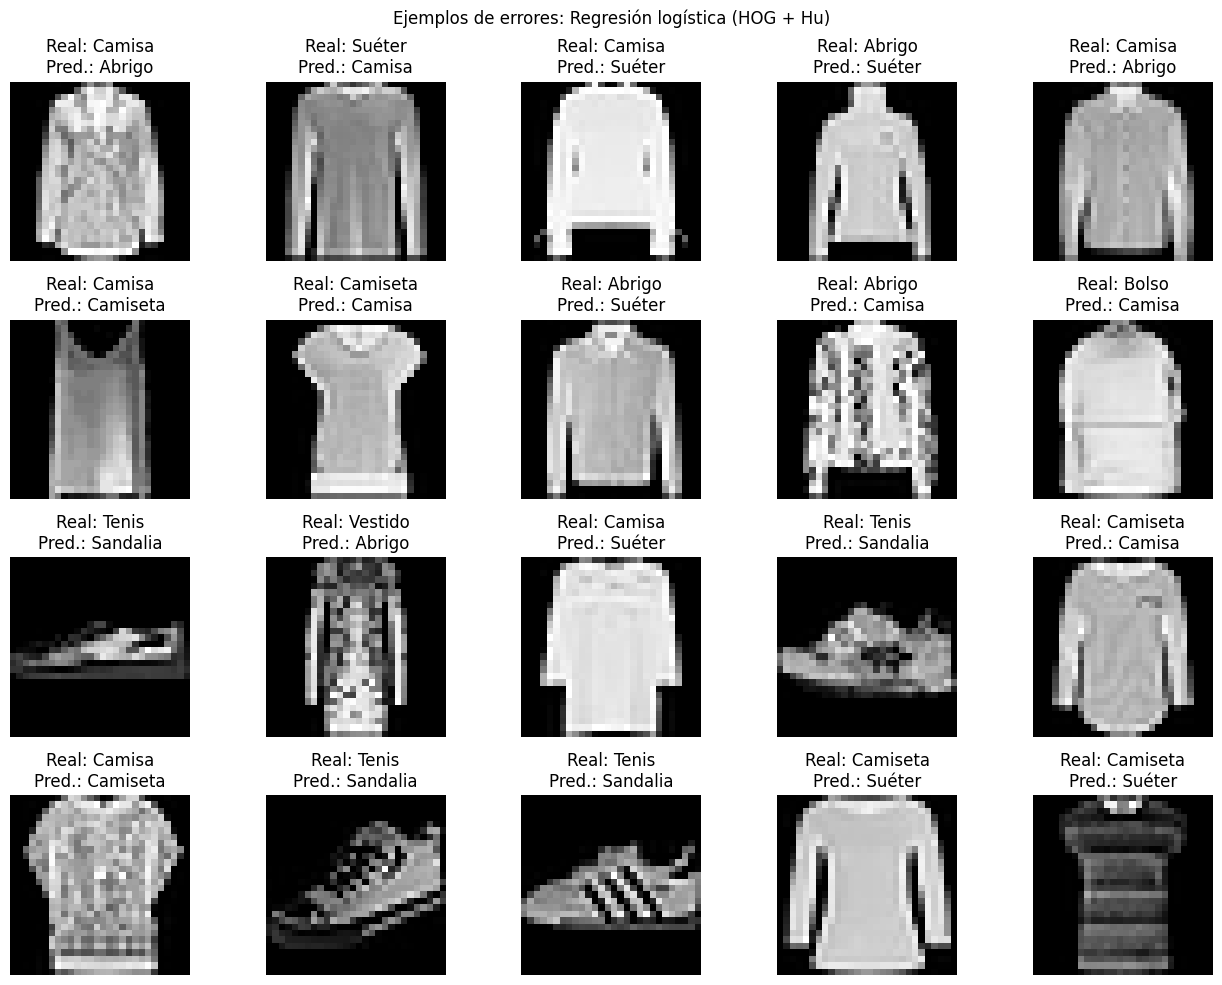


REPORTE DEL MODELO ELEGIDO
              precision    recall  f1-score   support

    Camiseta       0.84      0.84      0.84      1000
    Pantalón       0.97      0.97      0.97      1000
      Suéter       0.82      0.81      0.81      1000
     Vestido       0.88      0.88      0.88      1000
      Abrigo       0.80      0.83      0.81      1000
    Sandalia       0.97      0.95      0.96      1000
      Camisa       0.70      0.67      0.69      1000
       Tenis       0.92      0.95      0.94      1000
       Bolso       0.97      0.98      0.98      1000
       Botín       0.97      0.96      0.96      1000

    accuracy                           0.88     10000
   macro avg       0.88      0.88      0.88     10000
weighted avg       0.88      0.88      0.88     10000


TERMINADO
Carpeta: /content/StyleBot_modelos_resultados
ZIP: /content/StyleBot_modelos_resultados.zip
Modelo elegido: Regresión logística (HOG + Hu)


In [10]:
!pip -q install scikit-image

# ============================================================
# FASHION-MNIST: MODELOS, MÉTRICAS, FUENTES Y ENTREGABLES
# ============================================================

import time
import json
import shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC

from skimage.feature import hog
from skimage.measure import moments_central, moments_normalized, moments_hu


# ------------------------------------------------------------
# CONFIGURACIÓN
# ------------------------------------------------------------

SEMILLA = 42
N_COMPONENTES_PCA = 100
TAMANO_CV = 12000

np.random.seed(SEMILLA)

assert "X_train" in globals(), "Primero ejecuta las celdas originales de datos."
assert X_train.shape[0] == 48000
assert X_val.shape[0] == 12000
assert X_test.shape[0] == 10000

if "CATEGORIAS" not in globals():
    CATEGORIAS = [
        "Camiseta", "Pantalón", "Suéter", "Vestido", "Abrigo",
        "Sandalia", "Camisa", "Tenis", "Bolso", "Botín"
    ]

CARPETA = Path("StyleBot_modelos_resultados")
(CARPETA / "matrices_confusion").mkdir(parents=True, exist_ok=True)
(CARPETA / "errores").mkdir(parents=True, exist_ok=True)

X_train_flat = X_train.reshape(len(X_train), -1)
X_val_flat = X_val.reshape(len(X_val), -1)
X_test_flat = X_test.reshape(len(X_test), -1)

print("Entrenamiento:", X_train_flat.shape)
print("Validación:", X_val_flat.shape)
print("Prueba:", X_test_flat.shape)


# ------------------------------------------------------------
# FUNCIONES
# ------------------------------------------------------------

def obtener_metricas(y_real, y_pred):
    p_weighted, r_weighted, f1_weighted, _ = precision_recall_fscore_support(
        y_real, y_pred, average="weighted", zero_division=0
    )

    p_macro, r_macro, f1_macro, _ = precision_recall_fscore_support(
        y_real, y_pred, average="macro", zero_division=0
    )

    return {
        "accuracy": accuracy_score(y_real, y_pred),
        "precision_ponderada": p_weighted,
        "recall_ponderado": r_weighted,
        "f1_ponderado": f1_weighted,
        "precision_macro": p_macro,
        "recall_macro": r_macro,
        "f1_macro": f1_macro,
    }


def crear_logistica(C=1.0):
    return LogisticRegression(
        C=C,
        solver="lbfgs",
        max_iter=2000,
        tol=1e-3,
        random_state=SEMILLA,
    )


def crear_svm(C=0.1):
    return LinearSVC(
        C=C,
        dual=False,
        tol=1e-3,
        max_iter=3000,
        random_state=SEMILLA,
    )


def crear_random_forest(n_estimators=150, max_depth=None):
    return RandomForestClassifier(
        n_estimators=n_estimators,
        max_depth=max_depth,
        n_jobs=-1,
        random_state=SEMILLA,
    )


def crear_pipeline_base(nombre):
    if nombre == "Regresión logística":
        return Pipeline([
            ("escalador", StandardScaler()),
            ("modelo", crear_logistica()),
        ])

    if nombre == "SVM lineal":
        return Pipeline([
            ("escalador", StandardScaler()),
            ("modelo", crear_svm()),
        ])

    if nombre == "Random Forest":
        return Pipeline([
            ("modelo", crear_random_forest()),
        ])

    raise ValueError("Modelo no reconocido")


def crear_pipeline_ajuste(nombre, representacion):
    pasos = []

    if representacion == "PCA (100 componentes)":
        pasos.append((
            "pca",
            PCA(
                n_components=N_COMPONENTES_PCA,
                svd_solver="randomized",
                random_state=SEMILLA,
            ),
        ))

    if nombre == "Regresión logística":
        pasos.extend([
            ("escalador", StandardScaler()),
            ("modelo", crear_logistica()),
        ])

    elif nombre == "SVM lineal":
        pasos.extend([
            ("escalador", StandardScaler()),
            ("modelo", crear_svm()),
        ])

    elif nombre == "Random Forest":
        pasos.append(("modelo", crear_random_forest()))

    return Pipeline(pasos)


def extraer_hog_hu(imagenes, nombre):
    resultado = []

    for i, imagen in enumerate(imagenes):
        vector_hog = hog(
            imagen,
            orientations=9,
            pixels_per_cell=(4, 4),
            cells_per_block=(2, 2),
            block_norm="L2-Hys",
        )

        mu = moments_central(imagen)
        nu = moments_normalized(mu)
        hu = moments_hu(nu)

        # La escala logarítmica hace estables los valores de Hu.
        hu = np.sign(hu) * np.log1p(np.abs(hu))

        resultado.append(np.concatenate([vector_hog, hu]))

        if (i + 1) % 5000 == 0:
            print(f"{nombre}: {i + 1}/{len(imagenes)}")

    return np.asarray(resultado, dtype=np.float32)


# ------------------------------------------------------------
# 1. CLASIFICADOR PRELIMINAR
# ------------------------------------------------------------

idx_pequena, _ = train_test_split(
    np.arange(len(y_train)),
    train_size=5000,
    stratify=y_train,
    random_state=SEMILLA,
)

modelo_preliminar = Pipeline([
    ("escalador", StandardScaler()),
    ("modelo", crear_logistica()),
])

inicio = time.perf_counter()
modelo_preliminar.fit(X_train_flat[idx_pequena], y_train[idx_pequena])
tiempo_preliminar = time.perf_counter() - inicio

pred_preliminar = modelo_preliminar.predict(X_val_flat)
metricas_preliminares = obtener_metricas(y_val, pred_preliminar)

tabla_preliminar = pd.DataFrame([{
    "modelo": "Regresión logística",
    "representacion": "Píxeles crudos",
    "muestra_entrenamiento": 5000,
    "tiempo_segundos": tiempo_preliminar,
    "estado": "PRELIMINAR",
    **metricas_preliminares,
}])

print("\nRESULTADO PRELIMINAR")
display(tabla_preliminar)

tabla_preliminar.to_csv(
    CARPETA / "tabla_preliminar.csv",
    index=False,
    encoding="utf-8-sig",
)

fig, ejes = plt.subplots(2, 5, figsize=(12, 5))

for eje, indice in zip(ejes.ravel(), range(10)):
    eje.imshow(X_val[indice], cmap="gray")
    eje.set_title(
        f"Real: {CATEGORIAS[y_val[indice]]}\n"
        f"Pred.: {CATEGORIAS[pred_preliminar[indice]]}"
    )
    eje.axis("off")

fig.suptitle("Predicciones preliminares")
fig.tight_layout()
fig.savefig(CARPETA / "predicciones_preliminares.png", dpi=160)
plt.show()
plt.close(fig)


# ------------------------------------------------------------
# 2. PCA
# ------------------------------------------------------------

print("\nCalculando PCA...")

pca_base = PCA(
    n_components=N_COMPONENTES_PCA,
    svd_solver="randomized",
    random_state=SEMILLA,
)

X_train_pca = pca_base.fit_transform(X_train_flat)
X_val_pca = pca_base.transform(X_val_flat)

print(
    f"Varianza explicada por PCA: "
    f"{pca_base.explained_variance_ratio_.sum():.2%}"
)


# ------------------------------------------------------------
# 3. MODELOS BASE: PÍXELES CRUDOS Y PCA
# ------------------------------------------------------------

representaciones = {
    "Píxeles crudos": (X_train_flat, X_val_flat),
    "PCA (100 componentes)": (X_train_pca, X_val_pca),
}

nombres_modelos = [
    "Regresión logística",
    "SVM lineal",
    "Random Forest",
]

filas_base = []

for nombre_modelo in nombres_modelos:
    for nombre_representacion, (X_entrena, X_valida) in representaciones.items():
        print(f"\nEntrenando: {nombre_modelo} con {nombre_representacion}")

        modelo = crear_pipeline_base(nombre_modelo)

        inicio = time.perf_counter()
        modelo.fit(X_entrena, y_train)
        segundos = time.perf_counter() - inicio

        pred = modelo.predict(X_valida)
        metricas = obtener_metricas(y_val, pred)

        filas_base.append({
            "modelo": nombre_modelo,
            "representacion": nombre_representacion,
            "tiempo_segundos": segundos,
            "estado": "PRELIMINAR",
            **metricas,
        })

tabla_base = pd.DataFrame(filas_base).sort_values(
    "f1_macro",
    ascending=False,
).reset_index(drop=True)

print("\nTABLA COMPARATIVA PRELIMINAR")
display(tabla_base)

tabla_base.to_csv(
    CARPETA / "tabla_comparativa_preliminar.csv",
    index=False,
    encoding="utf-8-sig",
)

mejores_representaciones = (
    tabla_base.loc[
        tabla_base.groupby("modelo")["f1_macro"].idxmax(),
        ["modelo", "representacion"],
    ]
    .set_index("modelo")["representacion"]
    .to_dict()
)

print("\nMejores representaciones:")
print(mejores_representaciones)


# ------------------------------------------------------------
# 4. VALIDACIÓN CRUZADA Y AJUSTE
# ------------------------------------------------------------

idx_cv, _ = train_test_split(
    np.arange(len(y_train)),
    train_size=TAMANO_CV,
    stratify=y_train,
    random_state=SEMILLA,
)

X_cv = X_train_flat[idx_cv]
y_cv = y_train[idx_cv]

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=SEMILLA,
)

parametros_por_modelo = {
    "Regresión logística": {
        "modelo__C": [0.1, 1.0, 10.0],
    },
    "SVM lineal": {
        "modelo__C": [0.01, 0.1, 1.0],
    },
    "Random Forest": {
        "modelo__n_estimators": [100, 150],
        "modelo__max_depth": [None, 25],
    },
}

modelos_ajustados = {}
filas_ajuste = []

for nombre_modelo in nombres_modelos:
    representacion = mejores_representaciones[nombre_modelo]

    print(f"\nAjustando: {nombre_modelo} con {representacion}")

    busqueda = GridSearchCV(
        estimator=crear_pipeline_ajuste(nombre_modelo, representacion),
        param_grid=parametros_por_modelo[nombre_modelo],
        scoring="f1_macro",
        cv=cv,
        n_jobs=-1,
        refit=True,
        verbose=1,
    )

    inicio = time.perf_counter()
    busqueda.fit(X_cv, y_cv)
    segundos_cv = time.perf_counter() - inicio

    modelo_final_familia = clone(busqueda.best_estimator_)
    modelo_final_familia.fit(X_train_flat, y_train)

    pred_val = modelo_final_familia.predict(X_val_flat)
    metricas = obtener_metricas(y_val, pred_val)

    candidato = f"{nombre_modelo} ({representacion})"
    modelos_ajustados[candidato] = modelo_final_familia

    filas_ajuste.append({
        "candidato": candidato,
        "modelo": nombre_modelo,
        "representacion": representacion,
        "mejores_parametros": json.dumps(busqueda.best_params_),
        "f1_macro_cv": busqueda.best_score_,
        "tiempo_ajuste_cv_segundos": segundos_cv,
        **metricas,
    })


# ------------------------------------------------------------
# 5. LOGÍSTICA CON HOG + MOMENTOS DE HU
# ------------------------------------------------------------

print("\nExtrayendo HOG + Hu de entrenamiento...")
X_train_hog_hu = extraer_hog_hu(X_train, "Entrenamiento")

print("\nExtrayendo HOG + Hu de validación...")
X_val_hog_hu = extraer_hog_hu(X_val, "Validación")

pipeline_hog_hu = Pipeline([
    ("escalador", StandardScaler()),
    ("modelo", crear_logistica()),
])

busqueda_hog_hu = GridSearchCV(
    estimator=pipeline_hog_hu,
    param_grid={"modelo__C": [0.01, 0.1, 1.0, 10.0]},
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    refit=True,
    verbose=1,
)

print("\nAjustando regresión logística con HOG + Hu...")

inicio = time.perf_counter()
busqueda_hog_hu.fit(X_train_hog_hu[idx_cv], y_train[idx_cv])
segundos_hog_hu = time.perf_counter() - inicio

modelo_hog_hu = clone(busqueda_hog_hu.best_estimator_)
modelo_hog_hu.fit(X_train_hog_hu, y_train)

pred_val_hog_hu = modelo_hog_hu.predict(X_val_hog_hu)
metricas_hog_hu = obtener_metricas(y_val, pred_val_hog_hu)

nombre_hog_hu = "Regresión logística (HOG + Hu)"
modelos_ajustados[nombre_hog_hu] = modelo_hog_hu

filas_ajuste.append({
    "candidato": nombre_hog_hu,
    "modelo": "Regresión logística",
    "representacion": "HOG + momentos de Hu",
    "mejores_parametros": json.dumps(busqueda_hog_hu.best_params_),
    "f1_macro_cv": busqueda_hog_hu.best_score_,
    "tiempo_ajuste_cv_segundos": segundos_hog_hu,
    **metricas_hog_hu,
})

tabla_ajuste = pd.DataFrame(filas_ajuste).sort_values(
    "f1_macro",
    ascending=False,
).reset_index(drop=True)

print("\nRESULTADOS DESPUÉS DE VALIDACIÓN CRUZADA")
display(tabla_ajuste)

tabla_ajuste.to_csv(
    CARPETA / "tabla_ajuste_validacion_cruzada.csv",
    index=False,
    encoding="utf-8-sig",
)


# ------------------------------------------------------------
# 6. PRUEBA FINAL, MÉTRICAS MACRO Y MATRICES
# ------------------------------------------------------------

print("\nExtrayendo HOG + Hu de prueba...")
X_test_hog_hu = extraer_hog_hu(X_test, "Prueba")

filas_finales = []
predicciones_finales = {}

for candidato, modelo in modelos_ajustados.items():
    print(f"\nEvaluando en prueba: {candidato}")

    X_entrada = X_test_hog_hu if candidato == nombre_hog_hu else X_test_flat
    pred_prueba = modelo.predict(X_entrada)

    predicciones_finales[candidato] = pred_prueba
    metricas = obtener_metricas(y_test, pred_prueba)

    filas_finales.append({
        "candidato": candidato,
        **metricas,
    })

    matriz = confusion_matrix(y_test, pred_prueba)

    fig, eje = plt.subplots(figsize=(10, 8))
    ConfusionMatrixDisplay(
        confusion_matrix=matriz,
        display_labels=CATEGORIAS,
    ).plot(
        ax=eje,
        cmap="Blues",
        xticks_rotation=45,
        colorbar=False,
    )

    eje.set_title(f"Matriz de confusión: {candidato}")
    fig.tight_layout()

    archivo = (
        candidato
        .replace(" ", "_")
        .replace("(", "")
        .replace(")", "")
        .replace("+", "mas")
    )

    fig.savefig(
        CARPETA / "matrices_confusion" / f"{archivo}.png",
        dpi=180,
    )

    plt.show()
    plt.close(fig)

tabla_final = pd.DataFrame(filas_finales).sort_values(
    "f1_macro",
    ascending=False,
).reset_index(drop=True)

print("\nMÉTRICAS FINALES")
display(tabla_final)

tabla_final.to_csv(
    CARPETA / "metricas_finales_prueba.csv",
    index=False,
    encoding="utf-8-sig",
)


# ------------------------------------------------------------
# 7. ERRORES DEL MODELO SELECCIONADO
# ------------------------------------------------------------

modelo_elegido = tabla_ajuste.iloc[0]["candidato"]
pred_elegido = predicciones_finales[modelo_elegido]

errores = np.flatnonzero(pred_elegido != y_test)

print(f"\nModelo elegido por F1 macro de validación: {modelo_elegido}")
print(f"Cantidad de errores: {len(errores)}")

rng = np.random.default_rng(SEMILLA)
muestra_errores = rng.choice(
    errores,
    size=min(20, len(errores)),
    replace=False,
)

fig, ejes = plt.subplots(4, 5, figsize=(13, 10))

for eje, indice in zip(ejes.ravel(), muestra_errores):
    eje.imshow(X_test[indice], cmap="gray")
    eje.set_title(
        f"Real: {CATEGORIAS[y_test[indice]]}\n"
        f"Pred.: {CATEGORIAS[pred_elegido[indice]]}"
    )
    eje.axis("off")

fig.suptitle(f"Ejemplos de errores: {modelo_elegido}")
fig.tight_layout()
fig.savefig(
    CARPETA / "errores" / "ejemplos_de_errores.png",
    dpi=180,
)

plt.show()
plt.close(fig)

reporte = classification_report(
    y_test,
    pred_elegido,
    target_names=CATEGORIAS,
    zero_division=0,
)

print("\nREPORTE DEL MODELO ELEGIDO")
print(reporte)

(CARPETA / "reporte_clasificacion_modelo_elegido.txt").write_text(
    reporte,
    encoding="utf-8",
)


# ------------------------------------------------------------
# 8. README CON FUENTES Y EXPLICACIÓN DE CONVERGENCIA
# ------------------------------------------------------------

mejor_fila = tabla_final.iloc[0]

readme = f"""# Resultados de Fashion-MNIST

## Responsable
Ángel Uriel Martínez Godínez

## División de datos
- Entrenamiento: 48,000 imágenes.
- Validación: 12,000 imágenes.
- Prueba final: 10,000 imágenes.
- Semilla: {SEMILLA}.

## Modelos comparados
- Regresión logística.
- SVM lineal.
- Random Forest.
- Regresión logística con HOG y momentos de Hu.
- Píxeles crudos y PCA.

## Modelo elegido por validación
{modelo_elegido}

## Mejor resultado de prueba
- Candidato: {mejor_fila["candidato"]}
- Accuracy: {mejor_fila["accuracy"]:.4f}
- Precision ponderada: {mejor_fila["precision_ponderada"]:.4f}
- Recall ponderado: {mejor_fila["recall_ponderado"]:.4f}
- F1 ponderado: {mejor_fila["f1_ponderado"]:.4f}
- Precision macro: {mejor_fila["precision_macro"]:.4f}
- Recall macro: {mejor_fila["recall_macro"]:.4f}
- F1 macro: {mejor_fila["f1_macro"]:.4f}

## Convergencia
Las características de los modelos lineales se estandarizaron con
`StandardScaler`. También se configuró la regresión logística con
`max_iter=2000` y `tol=0.001`; esto da más iteraciones al optimizador
y reduce las advertencias de convergencia.

## Fuentes específicas
- Fashion-MNIST:
  https://www.tensorflow.org/api_docs/python/tf/keras/datasets/fashion_mnist/load_data
- LogisticRegression:
  https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html
- LinearSVC:
  https://scikit-learn.org/stable/modules/generated/sklearn.svm.LinearSVC.html
- RandomForestClassifier:
  https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html
- PCA:
  https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html
- GridSearchCV:
  https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html
- Métricas:
  https://scikit-learn.org/stable/modules/generated/sklearn.metrics.precision_recall_fscore_support.html
- HOG:
  https://scikit-image.org/docs/stable/api/skimage.feature.html#skimage.feature.hog
- Momentos de Hu:
  https://scikit-image.org/docs/stable/api/skimage.measure.html#skimage.measure.moments_hu
"""

(CARPETA / "README_resultados.md").write_text(
    readme,
    encoding="utf-8",
)

shutil.make_archive(
    "StyleBot_modelos_resultados",
    "zip",
    root_dir=CARPETA,
)

print("\n" + "=" * 60)
print("TERMINADO")
print("Carpeta:", CARPETA.resolve())
print("ZIP:", Path("StyleBot_modelos_resultados.zip").resolve())
print("Modelo elegido:", modelo_elegido)
print("=" * 60)